# pending writes와 장애 복구

**이 노트북에서 할 일**

1. 같은 단계에서 함께 실행되는 두 노드 가운데, 하나만 실패 흉내를 내게 합니다.
2. 실패한 뒤 읽은 체크포인트와 SQLite 파일의 표 `writes`에서, 성공한 노드의 결과가 남았는지 봅니다.
3. 원인을 없애고 `invoke(None, config)`로 이어 가, 성공한 노드가 다시 불렸는지 부른 횟수로 셉니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
01절처럼 매번 같은 값을 내는 우리 노드로, 저장된 값이 맞는지 출력으로 가릅니다.

실패는 모두 이 절에서 일부러 만든 실패 흉내입니다.
Ch 16 05절처럼 Python에 들어 있는 오류 `TimeoutError`를 냅니다.

노트북은 빈 임시 폴더를 만들어 그 폴더에서 실행합니다.
SQLite 파일은 이 임시 폴더에 생기고, 실습 폴더에는 파일을 남기지 않습니다.
읽어 오는 자료 파일은 없습니다.
교재 출력을 만든 실행에서는 노트북 전체가 5초 안에 끝났습니다.
설치 셀에 걸리는 시간은 네트워크에 따라 달라집니다.

**기준 버전** — 첫 셀에서 패키지 둘을 설치합니다.
그래프는 langgraph 1.2.11입니다.
SQLite 체크포인터는 langgraph-checkpoint-sqlite 3.0.3에 들어 있습니다.

교재 출력은 Linux의 Python 3.12.13과, 그 Python에 들어 있는 SQLite 3.53.1로 만들었습니다.
Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~5절을 읽습니다.
두 노드 가운데 하나만 실패시키고, 남은 것을 읽은 뒤 이어 가는 자리입니다.
6절은 같은 실패를 저장 시점 `exit`로 만드는 자리이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch23-persistence`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 상자 여섯이 한 줄로 이어진 흐름도입니다. 첫 파란 상자는 3절 graph.invoke 기본값으로 실행입니다. 둘째 노란 상자는 받은 오류 TimeoutError 부른 횟수 good 한 번 flaky 한 번입니다. 셋째 노란 상자는 get_state 다음 노드 flaky 하나 체크포인트 둘, 넷째 노란 상자는 4절 표 writes good 줄 results flaky 줄 __error__입니다. 다섯째 파란 상자는 5절 칸 fail을 False로 바꾼 뒤 graph.invoke None, 여섯째 노란 상자는 부른 횟수 good 한 번 flaky 두 번 결과 글 둘 모두 있음인 그림](attachment:05-2-실패에서-이어-가기까지의-차례.png)

위에서 아래로 한 줄로 읽습니다.
파란 상자는 우리가 부른 코드이고, 노란 상자는 노트북 3~5절 출력입니다.
둘째 상자부터 넷째 상자까지가 실패한 뒤 남은 것이고, 다섯째 상자에서 원인을 없애고 이어 갑니다.
맨 아래 상자에서 good의 부른 횟수는 둘째 상자와 같은 한 번입니다.
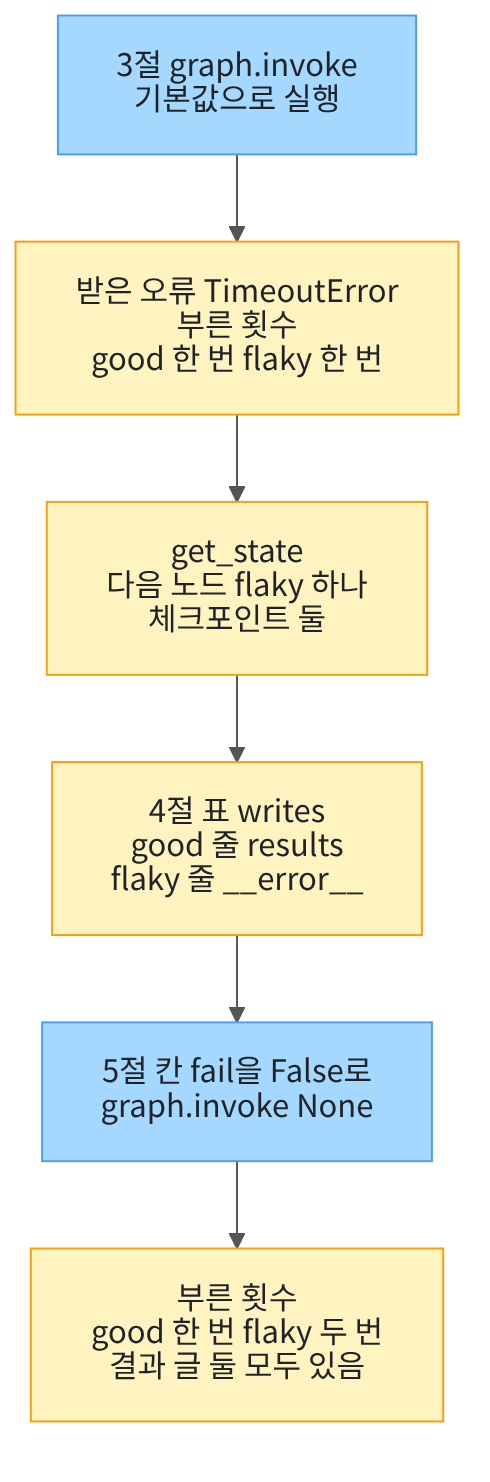

## 1. 준비

04절에서는 자식 프로세스를 강제로 끝낸 뒤, 파일에 남은 체크포인트로 다시 실행했습니다.
이 절은 강제 종료가 아니라, 노드 안의 오류로 멈춘 실행을 봅니다.
같은 단계에서 함께 실행되던 두 노드 가운데 하나만 실패하면, 성공한 쪽의 결과가 어떻게 되는지 확인합니다.

첫 셀은 패키지 둘을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11" "langgraph-checkpoint-sqlite==3.0.3"
from importlib.metadata import version

print("langgraph:", version("langgraph"))
print("langgraph-checkpoint-sqlite:", version("langgraph-checkpoint-sqlite"))

Note: you may need to restart the kernel to use updated packages.
langgraph: 1.2.11
langgraph-checkpoint-sqlite: 3.0.3


**결과 읽기** — 출력 줄 `langgraph: 1.2.11`과 `langgraph-checkpoint-sqlite: 3.0.3`이 보입니다.
두 판 모두 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-25에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
상태 형식과 그래프 이름은 Ch 13 01·02절, `sqlite3`와 `SqliteSaver`는 03절과 같습니다.
모듈 `time`은 Ch 16 05절에서 정한 초만큼 쉴 때 썼고, 이 절에서는 실패 흉내 앞에서 쉽니다.
모듈 `os`는 01절 임시 폴더 셀에서 썼습니다.

In [2]:
# 그래프 이름(Ch 13 01·02절)과 SQLite 체크포인터(03절)에, 실패 흉내 앞에서 쉴 모듈 time을 더해 가져옵니다
import operator
import os
import sqlite3
import time
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.sqlite import SqliteSaver

print("SQLite 판:", sqlite3.sqlite_version)

SQLite 판: 3.53.1


**결과 읽기** — 출력 줄 `SQLite 판: 3.53.1`은 03·04절과 같은 판입니다.

다음 셀은 01절처럼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다.
이 절의 SQLite 파일은 이 임시 폴더에 생깁니다.

In [3]:
# 파일이 생기는지 볼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다(Ch 4 03절과 같은 모양)
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고, 그 폴더의 위치를 글로 내놓습니다
practice_folder = tempfile.mkdtemp(prefix="ch23-05-")
# chdir()는 터미널의 cd처럼 현재 작업 폴더를 옮깁니다
os.chdir(practice_folder)
print("임시 폴더 이름에 ch23-05-이 들어 있는가:", "ch23-05-" in practice_folder)
print("현재 작업 폴더의 파일:", os.listdir())

임시 폴더 이름에 ch23-05-이 들어 있는가: True
현재 작업 폴더의 파일: []


**결과 읽기** — 출력 줄 `임시 폴더 이름에 ch23-05-이 들어 있는가: True`로, 이 절의 폴더를 만들었습니다.
출력 줄 `현재 작업 폴더의 파일: []`로, 빈 폴더에서 시작합니다.

## 2. 같은 단계에서 함께 실행되는 두 노드

이 절의 그래프는 가상 시작점에서 엣지 둘을 냅니다.
한 자리에서 엣지가 둘 나가면, 두 노드가 다음 단계에서 함께 실행됩니다.
Ch 20 03절에서 본 대로, 함께 실행되는 노드는 한 단계에 들어갑니다.
Ch 13 05절에서 한 흐름을 여러 갈래로 펼친 것처럼, 이번에는 고정 엣지 둘로 두 갈래를 냅니다.

두 노드는 같은 칸에 한꺼번에 갱신을 내므로, Ch 13 05절처럼 칸에 규칙이 있어야 합니다.
다음 셀은 칸 `results` 하나에 Ch 13 02절의 이어 붙이기 규칙 `operator.add`를 적은 상태 형식입니다.
04절의 `StepState`와 칸 이름이 달라, 새 이름 `ResultState`를 붙입니다.

In [4]:
# 칸 results 하나에 이어 붙이기 규칙을 적은 상태 형식을 만듭니다(Ch 13 02절 모양)
class ResultState(TypedDict):
    results: Annotated[list[str], operator.add]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
두 노드가 낸 목록은 규칙대로 칸의 목록 뒤에 함께 붙습니다.

다음 셀은 노드마다 부른 횟수를 셀 딕셔너리와, 실패 흉내를 정할 딕셔너리를 만듭니다.
Ch 16 05절에서 실패 흉내를 딕셔너리 `failure_plan`으로 정한 것과 같은 모양입니다.
칸 `fail`이 `True`인 동안 둘째 노드가 실패 흉내를 냅니다.
칸 `wait_seconds`는 실패 흉내를 내기 전에 기다릴 초입니다.

In [5]:
# 노드마다 부른 횟수를 셀 딕셔너리와, 실패 흉내를 정할 딕셔너리를 만듭니다(Ch 16 05절 모양)
call_count = {"good": 0, "flaky": 0}
# 칸 fail이 True인 동안 flaky는 wait_seconds초를 기다린 뒤 실패 흉내를 냅니다
failure_plan = {"fail": True, "wait_seconds": 0.1}
print("부른 횟수:", call_count)
print("실패 흉내:", failure_plan)

부른 횟수: {'good': 0, 'flaky': 0}
실패 흉내: {'fail': True, 'wait_seconds': 0.1}


**결과 읽기** — 출력 줄 `부른 횟수: {'good': 0, 'flaky': 0}`와 `실패 흉내: {'fail': True, 'wait_seconds': 0.1}`입니다.
두 노드는 이 두 딕셔너리를, 노트북에서 만든 이름 그대로 읽고 고칩니다.
부른 횟수는 우리 코드가 세는 값이라, 체크포인트에는 들어가지 않습니다.

다음 셀은 첫째 노드 `good`입니다.
Ch 17 01절의 `count = count + 1`처럼 부른 횟수에 1을 더합니다.
그리고 결과 글 하나를 목록에 담아 냅니다.

In [6]:
# 첫째 노드: 부른 횟수에 1을 더하고, 결과 글 하나를 목록에 담아 냅니다
def good(state):
    call_count["good"] = call_count["good"] + 1
    return {"results": ["good-result"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 둘째 노드 `flaky`입니다.
이름은 가끔 실패한다는 뜻의 영어 낱말에서 따왔습니다.
실패 흉내가 켜져 있으면 정한 초만큼 기다린 뒤 `TimeoutError`를 냅니다.
시간 초과는 기다린 끝에 나는 오류라, 실패 흉내도 잠시 기다린 뒤 냅니다.

기다리는 0.1초는 `good`이 먼저 끝나게 하려고 실행 전에 정한 값입니다.
노트북 밖 확인에서 `good`이 더 늦게 끝나게 하자, 저장 시점 `exit`는 `good`의 쓰기를 남기지 않았습니다.
그 장면은 이 노트북에서 실행하지 않았고, 교재 본문의 주의할 점에 적었습니다.

In [7]:
# 둘째 노드: 부른 횟수에 1을 더하고, 실패 흉내가 켜져 있으면 잠시 기다린 뒤 TimeoutError를 냅니다
def flaky(state):
    call_count["flaky"] = call_count["flaky"] + 1
    if failure_plan["fail"]:
        # 시간 초과처럼, 정한 초만큼 기다린 뒤 멈춥니다
        time.sleep(failure_plan["wait_seconds"])
        raise TimeoutError("이 절에서 만든 실패 흉내입니다.")
    return {"results": ["flaky-result"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
실패 흉내가 꺼져 있으면, 결과 글 하나를 목록에 담아 냅니다.

다음 셀은 설계 객체입니다.
가상 시작점에서 두 노드로 엣지 둘을, 두 노드에서 가상 끝점으로 엣지 둘을 적습니다.

In [8]:
# 가상 시작점에서 good과 flaky로 엣지 둘, 두 노드에서 가상 끝점으로 엣지 둘을 적습니다
builder = StateGraph(ResultState)
builder.add_node("good", good)
builder.add_node("flaky", flaky)
builder.add_edge(START, "good")
builder.add_edge(START, "flaky")
builder.add_edge("good", END)
builder.add_edge("flaky", END)
print("등록한 노드:", list(builder.nodes))
print("고정 엣지로 적은 수:", len(builder.edges))

등록한 노드: ['good', 'flaky']
고정 엣지로 적은 수: 4


**결과 읽기** — 출력 줄 `등록한 노드: ['good', 'flaky']`와 `고정 엣지로 적은 수: 4`입니다.
가상 시작점에서 나가는 엣지가 둘이라, 두 노드는 입력을 칸에 넣은 다음 단계에서 함께 실행됩니다.

다음 셀은 03절처럼 파일 `pending.sqlite`에 연결을 열고, SQLite 체크포인터를 붙여 컴파일합니다.

In [9]:
# 파일 pending.sqlite에 연결을 열고, SQLite 체크포인터를 붙여 설계 객체를 컴파일합니다(03절 모양)
pending_conn = sqlite3.connect("pending.sqlite", check_same_thread=False)
pending_saver = SqliteSaver(pending_conn)
graph = builder.compile(checkpointer=pending_saver)
print("붙은 체크포인터의 종류:", type(graph.checkpointer).__name__)

붙은 체크포인터의 종류: SqliteSaver


**결과 읽기** — 출력 줄 `붙은 체크포인터의 종류: SqliteSaver`입니다.

## 3. 한 노드만 실패한 실행

이제 스레드 `pending-a`로 그래프를 실행합니다.
저장 시점은 적지 않아, 04절에서 본 기본값 `async`로 실행됩니다.
둘째 노드가 실패 흉내를 내므로, Ch 16 05절처럼 `try/except`로 오류를 받아 출력합니다.
실행 전에 예상해 봅니다.
실행은 오류로 멈추지만, 두 노드는 모두 한 번씩 불렸을 것입니다.

In [10]:
# 스레드 pending-a로 실행하고, 둘째 노드가 낸 실패 흉내를 받아 출력합니다(저장 시점은 기본값)
config = {"configurable": {"thread_id": "pending-a"}}
try:
    graph.invoke({"results": []}, config)
except TimeoutError as error:
    print("오류 종류:", type(error).__name__)
    print("오류 메시지:", error)
print("부른 횟수:", call_count)

오류 종류: TimeoutError
오류 메시지: 이 절에서 만든 실패 흉내입니다.
부른 횟수: {'good': 1, 'flaky': 1}


**결과 읽기** — 출력 줄 `오류 종류: TimeoutError`와 `오류 메시지: 이 절에서 만든 실패 흉내입니다.`가 받은 오류입니다.
출력 줄 `부른 횟수: {'good': 1, 'flaky': 1}`로, 두 노드가 한 번씩 불렸습니다.
노드 `flaky`만 실패했고, 오류는 셀이 받아 출력해 노트북은 멈추지 않았습니다.

다음 셀은 01절에서 본 `get_state`로, 이 스레드의 마지막 체크포인트를 읽습니다.
체크포인트 목록도 받아 수를 셉니다.
실행 전에 생각해 봅니다.
노드 `good`은 결과를 냈지만 단계는 끝나지 못했는데, 그 결과는 어디에 보일까요?

In [11]:
# 실패한 뒤 스레드 pending-a의 마지막 체크포인트를 읽고, 체크포인트 수도 셉니다
failed_state = graph.get_state(config)
print("칸 값:", failed_state.values)
print("다음 노드:", failed_state.next)
failed_history = list(graph.get_state_history(config))
print("체크포인트 수:", len(failed_history))

칸 값: {'results': ['good-result']}
다음 노드: ('flaky',)
체크포인트 수: 2


**결과 읽기** — 출력 줄 `다음 노드: ('flaky',)`에는 `good`이 없습니다.
이어 갈 때 다시 실행할 노드는 `flaky` 하나라는 뜻입니다.
출력 줄 `칸 값: {'results': ['good-result']}`에는 노드 `good`의 결과가 보입니다.
출력 줄 `체크포인트 수: 2`는 입력을 받은 때와, 입력을 칸에 넣은 뒤의 둘입니다.

두 노드가 실행된 단계를 마친 뒤의 체크포인트는 없습니다.
그런데도 `good`의 결과가 어디에 남았는지, 다음 세 셀에서 찾습니다.

읽은 체크포인트의 `tasks`는 이 단계에서 할 작업의 목록입니다.
작업(task)은 한 단계에서 노드 하나를 한 번 실행하는 일입니다.
작업마다 노드 이름 `name`, 받은 오류 `error`, 낸 결과 `result`를 담고 있습니다.
다음 셀은 작업마다 세 값을 한 줄씩 출력합니다.

In [12]:
# 마지막 체크포인트의 작업마다 노드 이름·받은 오류·낸 결과를 한 줄씩 출력합니다
print("노드 | 받은 오류 | 낸 결과")
for task in failed_state.tasks:
    print(task.name, "|", task.error, "|", task.result)

노드 | 받은 오류 | 낸 결과
good | None | {'results': ['good-result']}
flaky | TimeoutError('이 절에서 만든 실패 흉내입니다.') | None


**결과 읽기** — 라벨 줄 아래 두 줄입니다.
줄 `good | None | {'results': ['good-result']}`는 오류 없이 결과를 낸 작업입니다.
줄 `flaky | TimeoutError('이 절에서 만든 실패 흉내입니다.') | None`은 결과 없이 오류만 남은 작업입니다.
받은 오류에는 오류 종류와 메시지가 함께 적혀 있습니다.

## 4. 파일에 남은 쓰기

03절에서 SQLite 체크포인터가 파일에 표 `checkpoints`와 `writes`를 만드는 것을 보았습니다.
표 `writes`는 작업이 낸 갱신을 한 줄씩 적는 표입니다.
설치판 소스에서 이 표의 칸 `task_id`에는 작업의 `id`를, 칸 `channel`에는 갱신한 칸 이름을 적습니다.
다음 셀은 한 작업이 이 표에 남긴 줄의 칸 이름을 읽는 함수입니다.

In [13]:
# 표 writes에서 한 스레드·한 작업이 남긴 줄의 칸 이름을 이름 차례로 읽어, 목록으로 내놓습니다
def saved_channels(connection, thread_name, task_id):
    sql = "SELECT channel FROM writes WHERE thread_id = ? AND task_id = ? ORDER BY channel"
    cursor = connection.execute(sql, [thread_name, task_id])
    channels = []
    # 줄마다 첫 칸이 칸 이름입니다
    for row in cursor.fetchall():
        channels.append(row[0])
    return channels

**결과 읽기** — 정의 셀이라 출력이 없습니다.
스레드 이름과 작업의 `id`는 Ch 4 03절처럼 자리표시자 `?`로 넘깁니다.
함수 모양은 03절의 `sqlite_tables`와 같고, 읽는 표와 조건만 다릅니다.

다음 셀은 실패한 뒤의 작업마다 이 함수를 부릅니다.
작업의 `id`는 체크포인트마다 새로 만들어져 실행마다 달라지므로, 출력하지 않고 조건으로만 씁니다.
실행 전에 예상해 봅니다.
노드 `good`의 줄에는 칸 `results`가 적혀 있을 것입니다.

In [14]:
# 실패한 뒤의 작업마다, 파일의 표 writes에 남은 줄의 칸 이름을 봅니다(작업의 id는 출력하지 않음)
print("노드 | 표 writes에 남은 칸 이름")
for task in failed_state.tasks:
    channels = saved_channels(pending_conn, "pending-a", task.id)
    print(task.name, "|", channels)

노드 | 표 writes에 남은 칸 이름
good | ['results']
flaky | ['__error__']


**결과 읽기** — 라벨 줄 아래 줄 `good | ['results']`는, 노드 `good`이 칸 `results`에 낸 갱신이 파일에 남았다는 뜻입니다.
줄 `flaky | ['__error__']`의 `__error__`는 라이브러리가 받은 오류를 적어 두는 이름입니다.
단계가 끝나지 않아 칸 값에 합쳐지지 못한 갱신이, 이렇게 체크포인트에 딸려 파일에 남습니다.
이 절은 이것을 남은 쓰기라고 부릅니다.

3절에서 읽은 칸 값에 `good`의 결과가 보인 것도 이 남은 쓰기 때문입니다.
설치판 소스에서 메서드 `get_state`는 마지막 체크포인트의 남은 쓰기를 칸 값에 더해 보여 줍니다.
다음 노드에서 `good`이 빠진 것도 같은 까닭으로, 쓰기가 남은 작업은 다시 실행할 노드에 넣지 않습니다.

## 5. 원인을 없애고 이어 가기

이제 실패 원인을 없앱니다.
이 절의 원인은 실패 흉내이므로, 칸 `fail`을 `False`로 바꿉니다.
실제 서비스라면 연결이 돌아오기를 기다리거나, 잘못된 설정을 고치는 일에 해당합니다.

In [15]:
# 실패 원인을 없앱니다: 칸 fail을 False로 바꿔 실패 흉내를 끕니다
failure_plan["fail"] = False
print("실패 흉내:", failure_plan)

실패 흉내: {'fail': False, 'wait_seconds': 0.1}


**결과 읽기** — 출력 줄 `실패 흉내: {'fail': False, 'wait_seconds': 0.1}`입니다.
체크포인트와 파일은 이 셀에서 바뀌지 않았습니다.

다음 셀이 이 절의 중심입니다.
04절 스크립트의 다시 실행 단계처럼, 입력 자리에 `None`을 넣어 부릅니다.
새 입력 없이, 이 스레드의 마지막 체크포인트부터 이어 갑니다.
실행 전에 예상해 봅니다.
남은 쓰기가 있는 `good`은 다시 불리지 않고, `flaky`만 다시 불릴 것입니다.

In [16]:
# 새 입력 없이(None) 같은 스레드를 이어 가고, 결과 목록과 부른 횟수를 봅니다
resumed = graph.invoke(None, config)
# 두 노드가 붙인 글의 차례는 결론에 쓰지 않으려고, 이름 차례로 정렬해 출력합니다
sorted_results = sorted(resumed["results"])
print("결과 목록(정렬):", sorted_results)
print("부른 횟수:", call_count)
# 부른 횟수는 우리 코드가 센 값이라 실행마다 같아야 합니다
assert call_count["good"] == 1, "good은 한 번만 불려야 합니다"
assert call_count["flaky"] == 2, "flaky는 두 번 불려야 합니다"

결과 목록(정렬): ['flaky-result', 'good-result']
부른 횟수: {'good': 1, 'flaky': 2}


**결과 읽기** — 출력 줄 `부른 횟수: {'good': 1, 'flaky': 2}`입니다.
이어 가는 동안 `flaky`만 한 번 더 불렸고, `good`은 다시 불리지 않았습니다.
출력 줄 `결과 목록(정렬): ['flaky-result', 'good-result']`에는 두 노드의 결과가 모두 있습니다.
노드 `good`의 결과는 다시 실행해 얻은 것이 아니라, 파일의 남은 쓰기를 붙인 것입니다.

마지막 두 줄의 `assert`도 통과했습니다.
04절의 `sync`는 끊긴 노드부터 이어 갔고, 이번에는 같은 단계 안에서도 실패한 작업만 다시 실행했습니다.

다음 셀은 이어 간 뒤의 마지막 체크포인트를 읽습니다.

In [17]:
# 이어 간 뒤 스레드 pending-a의 다음 노드·체크포인트 수·남은 작업 수를 봅니다
after_state = graph.get_state(config)
print("다음 노드:", after_state.next)
after_history = list(graph.get_state_history(config))
print("체크포인트 수:", len(after_history))
print("남은 작업 수:", len(after_state.tasks))

다음 노드: ()
체크포인트 수: 3
남은 작업 수: 0


**결과 읽기** — 출력 줄 `다음 노드: ()`와 `남은 작업 수: 0`으로, 이 스레드의 실행이 끝났습니다.
출력 줄 `체크포인트 수: 3`은 실패 전의 둘에, 두 노드의 단계를 마친 뒤의 하나가 더해진 수입니다.
실패한 단계를 처음부터 다시 만들지 않고, 그 단계의 체크포인트에서 이어 간 것입니다.

## 6. exit로 같은 실패 만들기

04절에서 저장 시점 `exit`는 강제로 끝낸 뒤 체크포인트를 하나도 남기지 않았습니다.
그때 설치판 소스에서 `exit`는 오류로 멈출 때도 나가면서 저장한다고 적었습니다.
이번에는 같은 실패를 `exit`로 만들어 확인합니다.
부른 횟수를 0으로 되돌리고 실패 흉내를 다시 켠 뒤, 새 스레드 `exit-run`으로 실행합니다.

In [18]:
# 부른 횟수를 0으로 되돌리고 실패 흉내를 켠 뒤, 저장 시점 exit로 새 스레드 exit-run을 실행합니다
call_count["good"] = 0
call_count["flaky"] = 0
failure_plan["fail"] = True
exit_config = {"configurable": {"thread_id": "exit-run"}}
try:
    graph.invoke({"results": []}, exit_config, durability="exit")
except TimeoutError as error:
    print("오류 종류:", type(error).__name__)
print("부른 횟수:", call_count)

오류 종류: TimeoutError
부른 횟수: {'good': 1, 'flaky': 1}


**결과 읽기** — 출력 줄 `오류 종류: TimeoutError`와 `부른 횟수: {'good': 1, 'flaky': 1}`은 3절과 같습니다.

다음 셀은 3·4절처럼 다음 노드와 체크포인트 수, 작업마다 표 `writes`에 남은 칸 이름을 봅니다.
실행 전에 예상해 봅니다.
값 `exit`가 오류로 멈출 때도 나가면서 저장한다면, 체크포인트가 하나 있을 것입니다.

In [19]:
# exit로 실패한 뒤의 다음 노드·체크포인트 수와, 작업마다 표 writes에 남은 칸 이름을 봅니다
exit_state = graph.get_state(exit_config)
print("다음 노드:", exit_state.next)
exit_history = list(graph.get_state_history(exit_config))
print("체크포인트 수:", len(exit_history))
print("노드 | 표 writes에 남은 칸 이름")
for task in exit_state.tasks:
    channels = saved_channels(pending_conn, "exit-run", task.id)
    print(task.name, "|", channels)

다음 노드: ('flaky',)
체크포인트 수: 1
노드 | 표 writes에 남은 칸 이름
good | ['results']
flaky | ['__error__']


**결과 읽기** — 출력 줄 `체크포인트 수: 1`은 값 `exit`가 나가면서 저장한 하나입니다.
출력 줄 `다음 노드: ('flaky',)`와 라벨 줄 아래 두 줄 `good | ['results']`·`flaky | ['__error__']`는 3·4절과 같습니다.
04절 강제 종료에서는 아무것도 남지 않았지만, 오류로 멈출 때는 체크포인트 하나에 남은 쓰기까지 저장했습니다.

다음 셀은 실패 흉내를 끄고, 같은 저장 시점 `exit`로 새 입력 없이 이어 갑니다.
실행 전에 예상해 봅니다.
5절처럼 `good`은 한 번, `flaky`는 두 번 불렸을 것입니다.

In [20]:
# 실패 흉내를 끄고, 저장 시점 exit로 새 입력 없이(None) 스레드 exit-run을 이어 갑니다
failure_plan["fail"] = False
exit_resumed = graph.invoke(None, exit_config, durability="exit")
exit_results = sorted(exit_resumed["results"])
print("결과 목록(정렬):", exit_results)
exit_history_after = list(graph.get_state_history(exit_config))
print("체크포인트 수:", len(exit_history_after))
print("부른 횟수:", call_count)

결과 목록(정렬): ['flaky-result', 'good-result']
체크포인트 수: 2
부른 횟수: {'good': 1, 'flaky': 2}


**결과 읽기** — 출력 줄 `부른 횟수: {'good': 1, 'flaky': 2}`와 `결과 목록(정렬): ['flaky-result', 'good-result']`는 5절과 같습니다.
출력 줄 `체크포인트 수: 2`는 실패할 때의 하나에, 끝날 때 저장한 하나가 더해진 수입니다.
체크포인트 수만 달랐고, 다시 실행한 노드는 기본값 `async`와 같았습니다.

다음 셀은 연결을 닫고, 작업 폴더에 남은 파일을 봅니다.

In [21]:
# 연결을 닫고, 작업 폴더에 남은 파일을 이름 차례로 봅니다
pending_conn.close()
file_names = sorted(os.listdir())
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: ['pending.sqlite']


**결과 읽기** — 출력 줄 `현재 작업 폴더의 파일: ['pending.sqlite']`입니다.
두 스레드는 한 파일에 함께 저장되었고, 연결을 닫아 옆 파일(`-wal`·`-shm`)은 남지 않았습니다.
파일은 임시 폴더에 있어, 실습 폴더에는 남지 않습니다.

## 정리

1. 같은 단계에서 `flaky`만 실패하자, 먼저 끝난 `good`의 결과가 남은 쓰기로 파일에 남았습니다.
2. 원인을 없애고 `invoke(None, config)`로 이어 가자, `good`은 다시 불리지 않고 `flaky`만 다시 불렸습니다.
3. 저장 시점 `exit`도 오류로 멈출 때 나가면서, 체크포인트 하나와 같은 남은 쓰기를 저장했습니다.

06절에서는 다시 실행된 노드가 체크포인트 밖에 한 쓰기를, 한 번만 반영하는 방법을 봅니다.